# 03 · Explicabilidad con SHAP

Se explica el **ganador ya seleccionado**, sobre una muestra de validación 2024 y con fondo de entrenamiento. No se usa test. SHAP se expresa en euros de renta municipal y describe el modelo, no causas económicas ni derechos a una ayuda.

`shap.Explainer` utiliza permutaciones sobre el espacio transformado del pipeline; permite explicar de forma homogénea cualquiera de los modelos seleccionados.

In [1]:
from pathlib import Path
import sys, os, json
import pandas as pd
import joblib
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'AGENTS.md').exists())
sys.path.insert(0, str(ROOT))
OUT = Path(os.getenv('RETO1_ARTIFACT_DIR', str(ROOT / 'entrega_ml')))
from src.ml_workflow import explain_validation, sha256
selection = json.loads((OUT / 'models/selection.json').read_text())
assert sha256(OUT / 'models/best_model.joblib') == selection['sha256_modelo']
model = joblib.load(OUT / 'models/best_model.joblib')
train = pd.read_csv(OUT / 'data/train.csv', dtype={'codigo_municipio': str})
val = pd.read_csv(OUT / 'data/val.csv', dtype={'codigo_municipio': str})
if not (OUT / 'resultados/shap_validacion.csv').exists():
    explain_validation(model, train, val, OUT / 'resultados')

,variable,media_abs_shap_eur
0,numericas__renta_lag1,53.970078
1,numericas__renta_lag4,24.661243
2,numericas__anio,21.399588
3,categoricas__provincia_Bizkaia,6.619326
4,numericas__contratos_lag1,5.687457
5,categoricas__codigo_municipio_20071,3.914086
6,numericas__trimestre,3.584149
7,categoricas__codigo_municipio_48054,2.915842
8,categoricas__codigo_municipio_20055,2.694159
9,categoricas__codigo_municipio_01059,2.630332


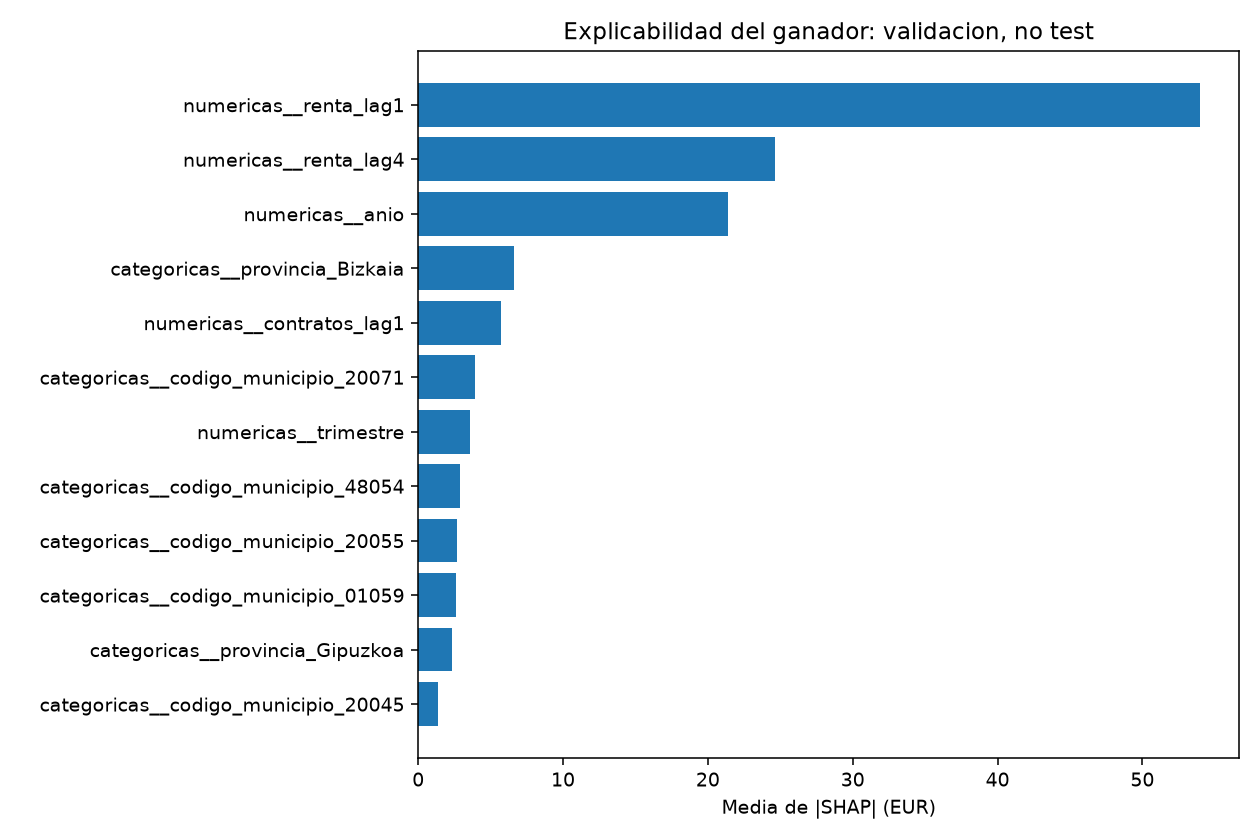

{'filas': 30,
 'indices_validacion': [605,
  664,
  611,
  601,
  636,
  662,
  629,
  613,
  670,
  665,
  635,
  643,
  650,
  619,
  610,
  623,
  606,
  634,
  657,
  667,
  640,
  641,
  617,
  645,
  646,
  631,
  608,
  659,
  648,
  632],
 'fondo': '30 filas de entrenamiento',
 'algoritmo': 'permutation',
 'unidad': 'EUR de renta municipal',
 'causal': False}

La mayor contribución absoluta media corresponde a **numericas__renta_lag1**: 53.97 EUR. Es magnitud media, no un efecto positivo constante.

In [2]:
importance = pd.read_csv(OUT / 'resultados/shap_validacion.csv')
display(importance)
display(Image(filename=str(OUT / 'resultados/shap_validacion.png')))
display(json.loads((OUT / 'resultados/shap_metadatos.json').read_text()))
first = importance.iloc[0]
display(Markdown(f"La mayor contribución absoluta media corresponde a **{first.variable}**: {first.media_abs_shap_eur:.2f} EUR. Es magnitud media, no un efecto positivo constante."))

## Límites y uso responsable

El ranking depende del modelo y del fondo elegido. Variables correlacionadas pueden compartir atribución. Una variable one-hot no se interpreta como una intervención causal sobre el municipio. Los resultados de un agregado municipal no justifican clasificar personas.

El motor de reglas separa la referencia de renta, el alquiler realmente declarado y la revisión de requisitos documentales. El flujo n8n registra una orientación, no una concesión o denegación administrativa.